In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_curve, roc_auc_score
import os, glob, re


from sklearn.model_selection import KFold

# Scores

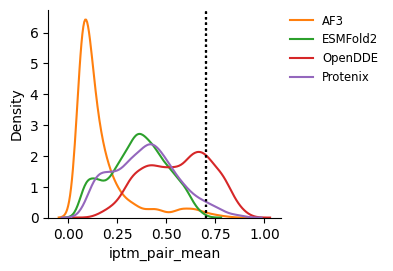

In [5]:
fig, ax = plt.subplots(1,1, figsize=(3,2.7), sharex=True, sharey=True)

methods = ['AF3', 'ESMFold2', 'OpenDDE', 'Protenix']
step = 'step0'
peptide = 'A0201_LLWNGPMAV'

# default seaborn/matplotlib palette, skipping the first color (blue)
colors = sns.color_palette()[1:len(methods)+1]

for method, color in zip(methods, colors):
    
    df1 = pd.read_csv(f'{method}/{peptide}/{step}/output_alpha.csv')[['ID', 'iptm_pair_mean']]
    df2 = pd.read_csv(f'{method}/{peptide}/{step}/output_beta.csv')[['ID', 'iptm_pair_mean']]
    df = pd.concat([df1, df2])
    sns.kdeplot(df, x='iptm_pair_mean', ax=ax, label=method, color=color)


    ax.axvline(x=0.7, color='black', linestyle=':')
    sns.despine()

ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, fontsize='small', frameon=False)

    

# AUC

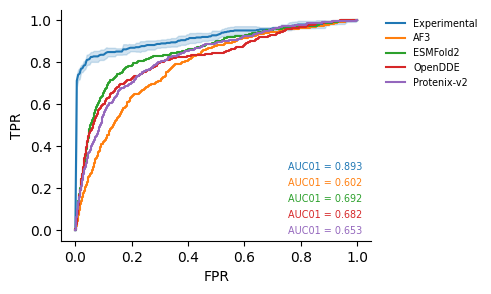

In [15]:
methods = ['AF3', 'ESMFold2', 'OpenDDE', 'Protenix']
step = 'step0'
peptide = 'A0201_LLWNGPMAV'

fig, ax = plt.subplots(1, 1, figsize=(4, 3))

# --- Experimental curve (5-fold CV: mean ROC + shaded error) ---
grid = np.linspace(0, 1, 201)
tprs, auc01s = [], []
for k in range(1, 6):
    dfk = pd.read_csv(f'../260626_ESMfold2_motif_builder/exp_data/{peptide}/exp_fold{k}_pred.csv')
    yk, sk = dfk['Label'].values, dfk['score'].values
    fpr, tpr, _ = roc_curve(yk, sk)
    tk = np.interp(grid, fpr, tpr); tk[0] = 0.0
    tprs.append(tk)
    auc01s.append(roc_auc_score(yk, sk, max_fpr=0.1))
tprs = np.vstack(tprs)
mean_tpr, sd_tpr = tprs.mean(0), tprs.std(0)
line, = ax.plot(grid, mean_tpr, label='Experimental')
ax.fill_between(grid, np.clip(mean_tpr - sd_tpr, 0, 1), np.clip(mean_tpr + sd_tpr, 0, 1),
                color=line.get_color(), alpha=0.2)
ax.text(0.97, 0.3, f"AUC01 = {np.mean(auc01s):.3f}",
        transform=ax.transAxes, ha='right', va='bottom',
        fontsize='x-small', color=line.get_color())

for cnt, method in enumerate(methods):

    df = pd.read_csv(
        f'{method}/{peptide}/{step}/validation/validation_pred.csv'
    )
    y_true, y_scores = df['Label'].values, df['score'].values
    fpr, tpr, _ = roc_curve(y_true, y_scores)
    auc01 = roc_auc_score(y_true, y_scores, max_fpr=0.1)

    method_label = method
    if method == "Protenix":
        method_label = "Protenix-v2"
    line, = ax.plot(fpr, tpr, label=f'{method_label}')
    
    ax.text(0.97, 0.23 - cnt * 0.07, f"AUC01 = {auc01:.3f}",
            transform=ax.transAxes, ha='right', va='bottom',
            fontsize='x-small', color=line.get_color())

    ax.set_xlabel('FPR')
    ax.set_ylabel('TPR')

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, fontsize='x-small', frameon=False,
                bbox_to_anchor=(1.02, 1), loc='upper left')

sns.despine()

plt.show()
